In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import label_binarize
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, roc_curve, roc_auc_score

In [2]:
df_raw = pd.read_csv("data/telescope_data.csv")
df = pd.DataFrame()
df = df_raw.drop(columns=df_raw.columns[0], inplace=False)
col_names = ["fLength","fWidth","fSize","fConc","fConc1","fAsym","fM3Long","fM3Trans","fAlpha","fDist","class"]
df.columns = col_names
df['class'] = label_binarize(df['class'], classes=['h', 'g']).ravel()

In [3]:
lowE = df[df["fSize"] < 3.0]
X = lowE.drop(columns=["class","fSize"],inplace=False)
class_labels = lowE["class"]

In [4]:
gamma_flag = (class_labels == 0)
gamma_lowE = lowE[gamma_flag]
cosmic_lowE = lowE[~gamma_flag]

def plot_pdf(gamma:pd.DataFrame, cosmic:pd.DataFrame ,nbins:int, xlabel:str, scale="linear") -> None:
    title = f"PDF of {xlabel}"
    plt.hist(gamma,bins=nbins,density=True, label="Gamma")
    plt.hist(cosmic,bins=nbins,alpha=0.5 ,density=True, label="Cosmic")
    #plt.xlim(llim,hlim)
    plt.xlabel(xlabel)
    plt.ylabel("Probability Density")
    plt.title(title)
    plt.yscale(scale)
    plt.legend()
    plt.show()


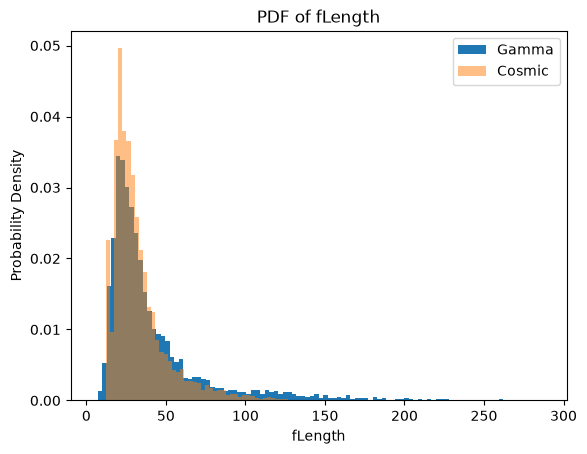

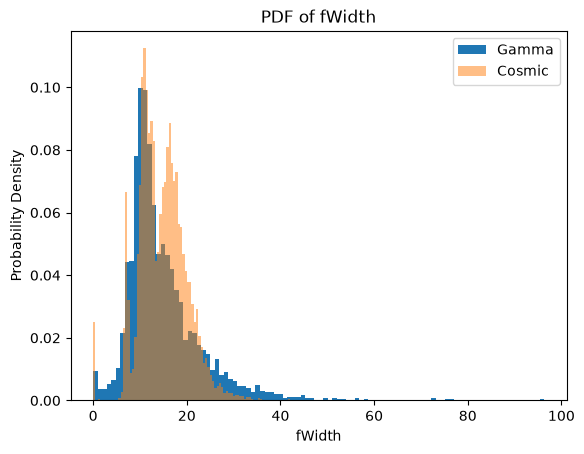

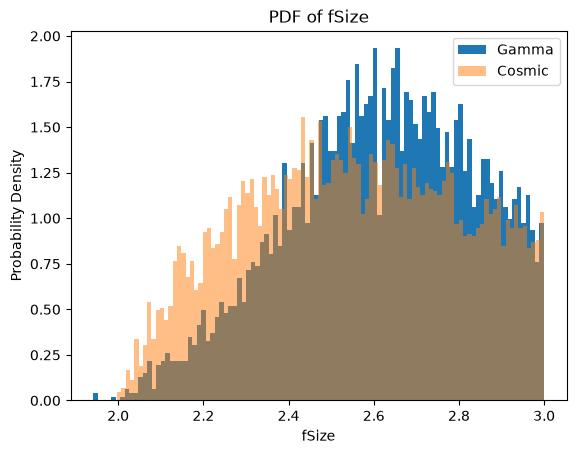

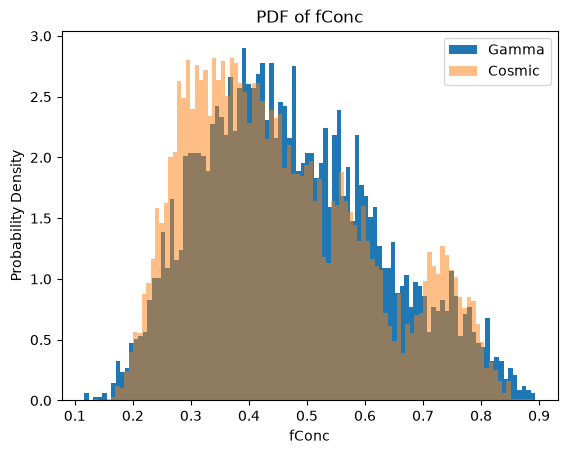

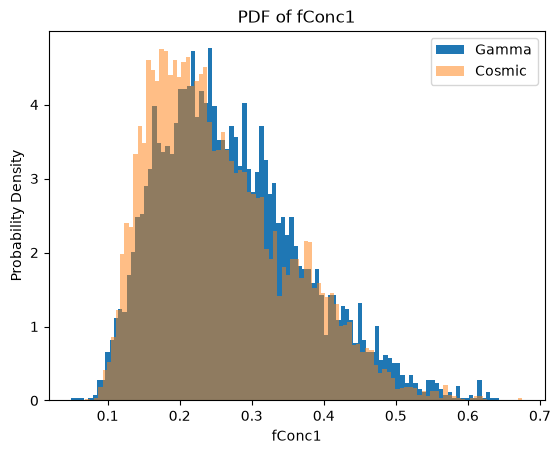

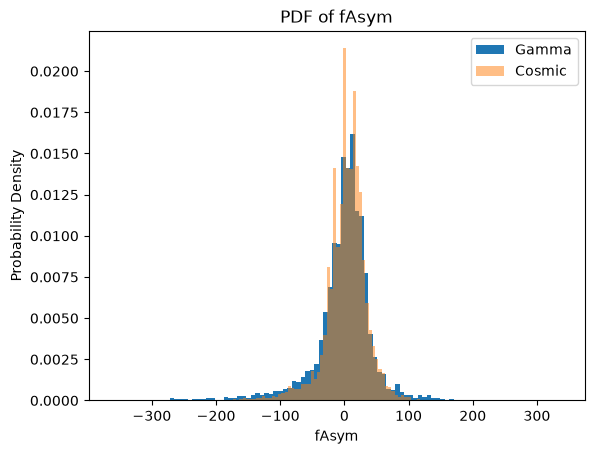

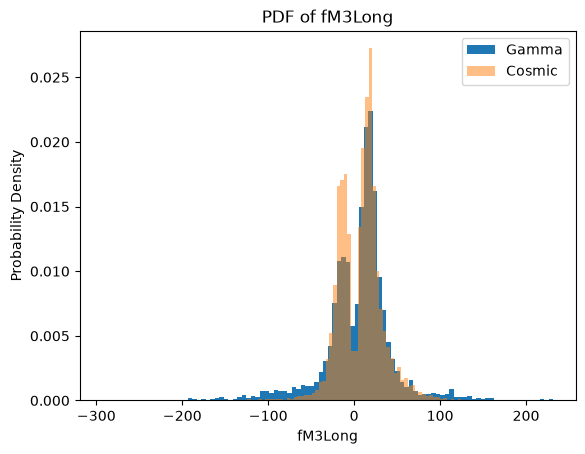

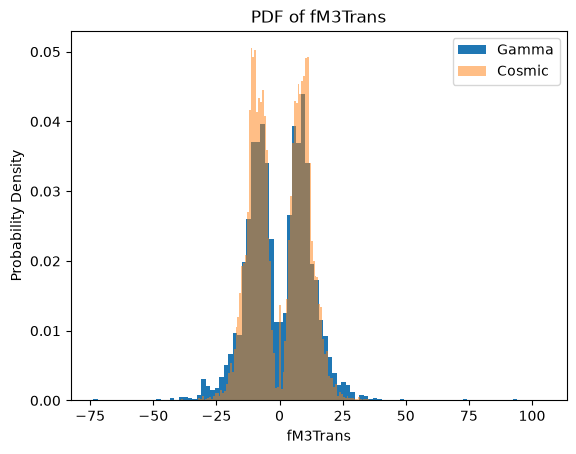

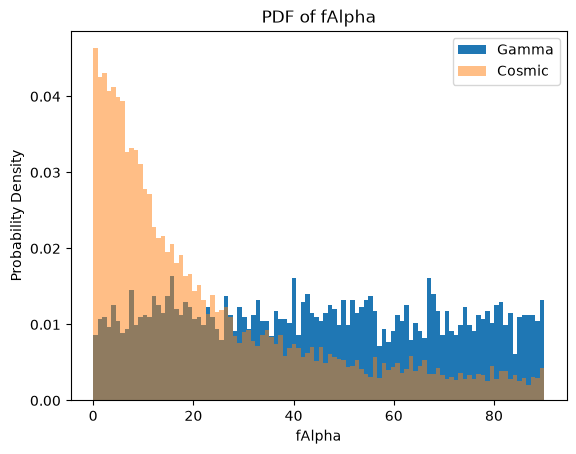

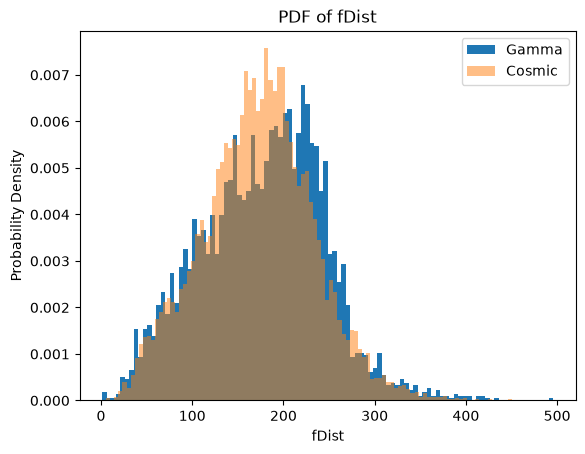

In [5]:
for col_name in lowE.columns[:-1]:
    plot_pdf(gamma_lowE[col_name], cosmic_lowE[col_name], 100, col_name)

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, class_labels, test_size=0.2, random_state=1, stratify=class_labels
)

I chose to do 20% for the test size arbitrarily. I chose to do stratify as I wanted to preserve the proportion of class labels in training and testing. Gamma occurs almost twice as much as Cosmic. I chose the random_state for it to be more reporoducible.

In [29]:
best_depth = 0
best_score = 0

auc_scores_test = []
auc_scores_train = []
max_depth_min = 1
max_depth_max = 50

md_list = list(range(max_depth_min,max_depth_max))
for md in md_list:
    D_tree = DecisionTreeClassifier(max_depth=md,min_samples_leaf=64,random_state=0)
    D_tree.fit(X_train,y_train)
    
    y_prob_test = D_tree.predict_proba(X_test)[:, 1]
    y_prob_train = D_tree.predict_proba(X_train)[:, 1]
    auc_test = roc_auc_score(y_test, y_prob_test)
    auc_train = roc_auc_score(y_train, y_prob_train)
    
    auc_scores_test.append(auc_test)
    auc_scores_train.append(auc_train)
    if auc > best_score:
        best_score = auc_test
        best_depth = md
        
print(f"Best AUC score on test data with max_depth {best_depth}: {best_score :.3f} \n")

Best AUC score on test data with max_depth 8: 0.811 



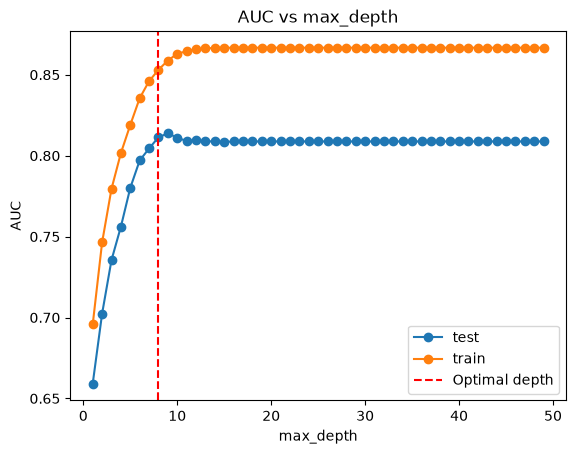

In [30]:
plt.plot(md_list, auc_scores_test, "-o", label="test")
plt.plot(md_list,auc_scores_train, "-o", label="train")
plt.xlabel("max_depth")
plt.ylabel("AUC")
plt.title("AUC vs max_depth")
plt.axvline(x=best_depth, color='red', linestyle='--', label='Optimal depth')
plt.legend()
plt.show()

The test AUC only plateaus after the best max_depth. Until then AUC on test grows. 

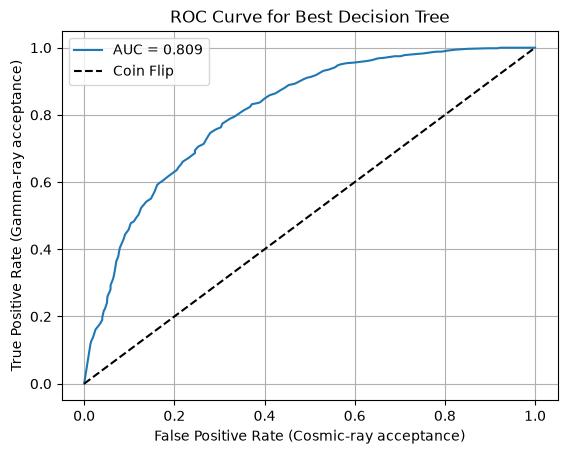

In [33]:
D_tree_best = DecisionTreeClassifier(max_depth=best_depth, min_samples_leaf=64,random_state=0)
D_tree_best.fit(X_train,y_train)

y_prob_test_best = D_tree.predict_proba(X_test)[:, 1]
auc_test_best = roc_auc_score(y_test, y_prob_test_best)
fpr,tpr,_ = roc_curve(y_test,y_prob_test_best)


plt.plot(fpr, tpr, '-', label=f'AUC = {auc_test_best:.3f}')
plt.plot([0, 1], [0, 1], 'k--', label='Coin Flip')
plt.xlabel('False Positive Rate (Cosmic-ray acceptance)')
plt.ylabel('True Positive Rate (Gamma-ray acceptance)')
plt.title("ROC Curve for Best Decision Tree")
plt.legend()
plt.grid()
plt.show()